---
title: "October-December 2023 by dekad, one to three dekads ahead"
subtitle: "Subseasonal rainfall forecasts for Indonesia from GEFSv12, calibrated with CCA and PCR through CPT"
description: "Build dekad CHIRPS v3.0 observations, turn daily GEFSv12 hindcasts and forecasts into dekad totals at three leads, fit CCA and PCR with cptcore, and measure skill by lead and the 2023 outcome."
execute:
  enabled: false
---

Cases 03 and 04 asked how a forecast for November and for October-December 2023
changes when it is made one to six **months** ahead. This notebook asks the same
question one time scale shorter: rainfall over a **dekad** (about ten days),
forecast one, two and three dekads ahead, for every dekad of October-December.

Dekads (*dasarian*) are the unit BMKG, Indonesia's meteorological agency, uses for
its rainfall early warnings, and the CHIRPS v3.0 archive used throughout this tutorial
is stored in dekads. The design below (lead rule, model, years, settings, scores)
was fixed before any skill was computed.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, the CHIRPS v3.0 dekadal archive
from the monthly case, and internet access the first time: 293 GEFSv12 files
(about 1.2 GB) from the IRI Data Library, no key needed. The six CPT fits take
about ten minutes.
:::

## 1. Model, starts and the lead rule

PyCPT 2.10.4's subseasonal catalog has one model, **GEFSv12** (NOAA's Global
Ensemble Forecast System), through the IRI Data Library. Its hindcasts start on
**Wednesdays** with 11 members and daily values up to 35 days ahead; its real-time
forecasts start every day with 31 members.

Dekads follow the calendar (days 1-10, 11-20 and 21 to the end of the month) while
the hindcasts start on Wednesdays, so "one dekad ahead" needs a precise rule. Here
**lead k** is the dekad that begins 7(k-1)+1 to 7k days after a Wednesday start:

| Lead | Dekad begins after the start | Latest model day used |
| --- | --- | --- |
| 1 | 1 to 7 days | 18 |
| 2 | 8 to 14 days | 25 |
| 3 | 15 to 21 days | 32 |

Each window holds exactly one Wednesday, so every October-December dekad gets
exactly one forecast at each lead, and the three leads are scored on the **same
target dekads**. A fourth lead would need model days beyond 35. The cell builds
the table of targets and starts.

In [1]:
from pathlib import Path
import datetime as dt
import json
import shutil
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
from cptcore import canonical_correlation_analysis, principal_components_regression

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.country_grid import aggregate_country_rainfall
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import download_gefs_dekads as gefs_source
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-dekads"
training_years = list(range(2000, 2019))
leads = [1, 2, 3]
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=17,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))


def ond_dekads(year):
    out = []
    for month in (10, 11, 12):
        following = dt.date(year + (month == 12), month % 12 + 1, 1)
        out += [(dt.date(year, month, 1), dt.date(year, month, 11)),
                (dt.date(year, month, 11), dt.date(year, month, 21)),
                (dt.date(year, month, 21), following)]
    return out


rows = []
for year in training_years + [2023]:
    for first, end in ond_dekads(year):
        for lead in leads:
            starts = [first - dt.timedelta(days=d) for d in range(7 * (lead - 1) + 1, 7 * lead + 1)
                      if (first - dt.timedelta(days=d)).weekday() == 2]
            assert len(starts) == 1
            rows.append({"year": year, "dekad": first, "end": end, "lead": lead, "start": starts[0],
                         "kind": "forecast" if year == 2023 else "hindcast",
                         "first_day": (first - starts[0]).days, "days": (end - first).days})
design = pd.DataFrame(rows)
design["last_day"] = design["first_day"] + design["days"] - 1
print(f"{design.dekad.nunique()} target dekads ({design[design.kind == 'hindcast'].dekad.nunique()} training, "
      f"{design[design.kind == 'forecast'].dekad.nunique()} in 2023); "
      f"{design.start.nunique()} distinct starts; latest model day used: {design['last_day'].max()}")
design.groupby("lead")[["first_day", "last_day"]].agg(["min", "max"])

180 target dekads (171 training, 9 in 2023); 293 distinct starts; latest model day used: 31


first_day     last_day    
           min max      min max
lead                           
1            1   7       10  17
2            8  14       17  24
3           15  21       24  31

## 2. Observations: dekad totals

The predictand is CHIRPS v3.0 dekad rainfall from the same local archive as the
monthly case, on the tutorial's 0.25° Indonesia land grid
([chapter 3](../learn/03-local-observations.ipynb)). The archive stores each
dekad's time bounds and keeps exact zeros; the cell checks the bounds before use.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
stamps = pd.DatetimeIndex(source.time.values)
index = np.flatnonzero(stamps.year.isin(training_years + [2023]) & stamps.month.isin([10, 11, 12]))
bounds = pd.DatetimeIndex(source.time_bnds.isel(time=index).values.ravel()).values.reshape(-1, 2)
first_day, end_day = pd.DatetimeIndex(bounds[:, 0]), pd.DatetimeIndex(bounds[:, 1])
assert (first_day == stamps[index]).all() and (first_day.date == np.array(sorted(design.dekad.unique()))).all()
assert (end_day.date == np.array([e for _, e in sorted({(d, e) for d, e in zip(design.dekad, design.end)})])).all()
print(f"{len(index)} dekads with stored bounds matching the design; lengths {sorted(set((end_day - first_day).days))} days")

box = predictand_extent
start = time.monotonic()
native = (source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))
          .isel(time=index).load())
print(f"Read {dict(native.sizes)} in {time.monotonic() - start:.0f} s; negative values: {int((native < 0).sum())}")

records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(native.lon, native.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": native.lat, "lon": native.lon})
print("Indonesian pixel-dekads at exactly 0 mm:", int(((native == 0) & country).sum()))

centres_y = box["south"] + 0.125 + np.arange(76) * 0.25
centres_x = box["west"] + 0.125 + np.arange(192) * 0.25
obs = xr.concat([aggregate_country_rainfall(native.isel(time=i, drop=True), country, 5, minimum_coverage=0.99)
                 .precipitation.rename({"lat": "Y", "lon": "X"}).assign_coords(Y=centres_y, X=centres_x)
                 .sortby("Y", ascending=False) for i in range(native.sizes["time"])],
                dim=pd.Index(first_day, name="T"))
train = obs["T"].dt.year < 2019
cells = obs.where(train, drop=True).notnull().all("T")
obs = obs.where(cells)
weights = np.cos(np.deg2rad(obs["Y"])) * cells
print(f"Cells complete in all {int(train.sum())} training dekads: {int(cells.sum())}")

180 dekads with stored bounds matching the design; lengths [10, 11] days


Read {'time': 180, 'lat': 380, 'lon': 960} in 42 s; negative values: 0


Indonesian pixel-dekads at exactly 0 mm: 160629


Cells complete in all 171 training dekads: 3240


## 3. Model: daily GEFSv12 to dekad totals

The download uses this tutorial's
[GEFS script](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/download_gefs_dekads.py):
one request per start for the predictor box 85-155°E, 20°S-20°N (as in the
seasonal cases), all members and daily slots 1.5 to 31.5 days. It skips files that
are already complete and checks units, members, lead slots and grid for each.

In [3]:
raw_dir = case_root / "gefs"
raw_dir.mkdir(parents=True, exist_ok=True)
jobs = sorted({(k, s) for k, s in zip(design.kind, design.start)}, key=lambda j: (j[0] != "hindcast", j[1]))
fetched = 0
for kind, start_date in jobs:
    path = raw_dir / f"gefs-{kind}-{start_date.isoformat()}.nc"
    if path.exists() and gefs_source.check(path, kind, start_date) is None:
        continue
    gefs_source.fetch(gefs_source.url_for(kind, start_date), path)
    problem = gefs_source.check(path, kind, start_date)
    assert problem is None, f"{path.name}: {problem}"
    fetched += 1
print(f"{len(jobs)} starts ({sum(k == 'hindcast' for k, _ in jobs)} hindcasts, {sum(k == 'forecast' for k, _ in jobs)} forecasts); "
      f"downloaded now: {fetched}; all checked")

293 starts (278 hindcasts, 15 forecasts); downloaded now: 0; all checked


The two branches store rainfall differently: hindcasts as the amount per day
(kg m⁻², which is mm), forecasts as a rate (kg m⁻² s⁻¹), converted with 86,400
seconds per day. The units are read from each file's `units` attribute, which
the download script checks for every start.
For each target dekad and lead, the cell sums the daily values over the dekad's
days and averages the members, refusing any missing or negative value.

In [4]:
factor = {"hindcast": 1.0, "forecast": 86400.0}
fields, missing, negative = [], 0, 0
for row in design.itertuples():
    slots = np.arange(row.first_day, row.first_day + row.days) + 0.5          # day d after the start is slot L = d + 0.5
    with xr.open_dataset(raw_dir / f"gefs-{row.kind}-{row.start.isoformat()}.nc", decode_timedelta=False) as ds:
        daily = ds["pr"].isel(S=0, drop=True).sel(L=slots).load()
    missing += int((~np.isfinite(daily)).sum())
    negative += int((daily < 0).sum())
    total = (daily * factor[row.kind]).sum("L", skipna=False).mean("M", skipna=False)
    fields.append(total.assign_coords(lead=row.lead, T=pd.Timestamp(row.dekad)))
assert missing == 0 and negative == 0
gefs = (xr.concat(fields, dim="sample").set_index(sample=["lead", "T"]).unstack("sample")
        .transpose("lead", "T", "Y", "X").sortby("Y", ascending=False))
assert (gefs["T"].values == obs["T"].values).all()
print(f"GEFS dekad totals {dict(gefs.sizes)}; missing values {missing}, negative values {negative}")

GEFS dekad totals {'lead': 3, 'T': 180, 'Y': 41, 'X': 71}; missing values 0, negative values 0


## 4. Anomalies, and three things CPT needs

October-December rainfall rises through the season, so a correlation over all
dekads would partly measure that seasonal rise rather than forecast skill. Both
the model and the observations are therefore turned into **anomalies**: the
difference from the 2000-2018 mean of the same calendar dekad (and, for the model,
the same lead). The same means are subtracted from the 2023 values.

These means use all 19 training years, including the year held out in
cross-validation. For correlations this makes no difference: leaving a year out of
its own dekad mean multiplies every anomaly by the same factor (19/18), so the
raw-model correlations come out identical either way. Inside CPT's cross-validated fits it shifts each fold's training
anomalies slightly; that effect was not measured.

In [5]:
key = obs["T"].dt.strftime("%m-%d")
y_clim = obs.where(train, drop=True).groupby(key.where(train, drop=True)).mean("T")
y_anom = obs.groupby(key) - y_clim
x_anom = {}
for lead in leads:
    x = gefs.sel(lead=lead, drop=True)
    x_anom[lead] = x.groupby(key) - x.where(train, drop=True).groupby(key.where(train, drop=True)).mean("T")

area = lambda f: float(f.where(cells).weighted(weights).mean(("Y", "X")))
seasonal = y_clim.weighted(weights).mean(("Y", "X"))
print("2000-2018 mean dekad rainfall over Indonesian cells (mm):",
      dict(zip(seasonal["strftime"].values, np.round(seasonal.values, 1))))

2000-2018 mean dekad rainfall over Indonesian cells (mm): {'10-01': np.float64(69.9), '10-11': np.float64(69.8), '10-21': np.float64(87.5), '11-01': np.float64(83.8), '11-11': np.float64(92.6), '11-21': np.float64(94.6), '12-01': np.float64(95.0), '12-11': np.float64(95.3), '12-21': np.float64(109.2)}


Getting CPT to fit these samples took three adjustments, each found by a failed
run while preparing this case:

1. **Dates.** With the real dekad dates (steps of 10 or 11 days, then a jump to the
   next October) the CPT process stopped while reading its input. As PyCPT's own
   `redate` does for its in-sample fit ([chapter 4](../learn/04-evaluate-models.ipynb)),
   the samples get **placeholder years**, 1801 onwards, all labelled 1-10 October,
   in the original order. Cross-validation depends only on that order. The real
   dates are kept alongside in Python.
2. **Field name.** CPT refused negative values in fields named `precipitation`
   ("Data contain negative values when zero-bound is set"). Anomalies are
   negative half the time, so the fields are named `anomaly`.
3. **Latitude order.** `cptcore` matches CPT's output grid to the input grid and
   expects latitudes from north to south, while the IRI files run south to north;
   the predictor was sorted above.

**Cross-validation window**: 17 samples. With 9 dekads per year, leaving out the
held-out dekad and the 8 on each side removes at least the rest of its own
October-December season, so a training fit never sees another dekad of the same
season.

In [6]:
def cpt_ready(a, real_times, first_year):
    years = first_year + np.arange(len(real_times))
    a = a.drop_vars([c for c in a.coords if c not in ("T", "Y", "X")]).sel(T=real_times)
    a = a.assign_coords(T=pd.to_datetime([f"{y}-10-05" for y in years]))
    a = a.assign_coords(Ti=("T", pd.to_datetime([f"{y}-10-01" for y in years])),
                        Tf=("T", pd.to_datetime([f"{y}-10-10" for y in years])))
    a = a.transpose("T", "Y", "X").rename("anomaly")
    a.attrs = {"units": "mm", "missing": -999.0, "long_name": "dekad rainfall anomaly"}
    return a


train_T = obs["T"].values[train.values]
test_T = obs["T"].values[~train.values]
Y = cpt_ready(y_anom.where(obs.notnull()), train_T, 1801)
inputs = {lead: (cpt_ready(x_anom[lead], train_T, 1801), cpt_ready(x_anom[lead], test_T, 1990)) for lead in leads}
print("Y", dict(Y.sizes), "| X", dict(inputs[1][0].sizes), "| F", dict(inputs[1][1].sizes))
print("placeholder dates:", str(Y["T"].values[0])[:10], "to", str(Y["T"].values[-1])[:10],
      "for", str(train_T[0])[:10], "to", str(train_T[-1])[:10])

Y {'T': 171, 'Y': 76, 'X': 192} | X {'T': 171, 'Y': 41, 'X': 71} | F {'T': 9, 'Y': 41, 'X': 71}
placeholder dates: 1801-10-05 to 1971-10-05 for 2000-10-01 to 2018-12-21


## 5. Six fits

CCA (3 predictor and 3 predictand EOFs, 2 CCA modes) and PCR (3 predictor EOFs)
at each lead, through `cptcore`, the layer PyCPT's `evaluate_models` calls
([chapter 4](../learn/04-evaluate-models.ipynb)). PyCPT's own subseasonal driver
is not used: in this version it fails on a fresh download and has no PCR. Each fit
writes CPT's files to its own folder.

In [7]:
results = {}
for lead in leads:
    X, F = inputs[lead]
    for method, function, method_settings in [("CCA", canonical_correlation_analysis, cca_settings),
                                              ("PCR", principal_components_regression, settings)]:
        folder = case_root / f"cpt-lead{lead}-{method.lower()}"
        shutil.rmtree(folder, ignore_errors=True)
        folder.mkdir(parents=True)
        start = time.monotonic()
        hindcast, forecast, skill = function(X, Y, F=F, **method_settings, cpt_kwargs={"outputdir": folder})[:3]
        results[lead, method] = dict(hindcast=hindcast, forecast=forecast, skill=skill, seconds=time.monotonic() - start)
print("Seconds per fit:", {f"{lead}-{m}": round(r["seconds"]) for (lead, m), r in results.items()})

Seconds per fit: {'1-CCA': 98, '1-PCR': 59, '2-CCA': 98, '2-PCR': 59, '3-CCA': 97, '3-PCR': 59}


Two checks on what came back: the hindcasts keep negative anomalies (nothing was
clipped at zero), and CPT's correlation map equals a correlation recomputed from
its own cross-validated hindcasts.

In [8]:
def clean(a):
    return a.where(a > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3)


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


y_plain = Y.drop_vars(["Ti", "Tf"])
rows = []
for (lead, method), r in results.items():
    det = clean(r["hindcast"].deterministic).drop_vars([c for c in r["hindcast"].deterministic.coords if c not in ("T", "Y", "X")])
    mine = pearson(det.assign_coords(T=y_plain["T"].values), y_plain)
    rows.append({"lead": lead, "method": method, "hindcast values below 0 (%)": round(float((det < 0).sum() / det.notnull().sum() * 100), 1),
                 "largest gap, CPT vs recomputed correlation": float(np.nanmax(np.abs((clean(r["skill"].pearson) - mine).where(cells).values)))})
pd.DataFrame(rows).set_index(["lead", "method"])

hindcast values below 0 (%)  \
lead method                                
1    CCA                            50.2   
     PCR                            50.2   
2    CCA                            50.4   
     PCR                            50.7   
3    CCA                            51.6   
     PCR                            51.6   

             largest gap, CPT vs recomputed correlation  
lead method                                              
1    CCA                                   7.391589e-07  
     PCR                                   7.502959e-07  
2    CCA                                   8.722155e-07  
     PCR                                   8.732644e-07  
3    CCA                                   7.928411e-07  
     PCR                                   9.174603e-07

## 6. Skill by lead

Cross-validated scores over the 171 training dekads, summarised as area-weighted
means over the 3,240 cells (weights: cosine of latitude):

- **Pearson correlation** of hindcast and observed anomalies; 0 is no linear relationship.
- **2AFC**: the chance (in %) that the hindcasts rank two different dekads in the observed order; 50% is no skill.

The **raw GEFS** baseline is the model's own anomaly, interpolated from 1° to the
cell centres, correlated with the observed anomalies. It involves no fitting, so
it pays none of the cost that cross-validation charges the calibrated forecasts.

In [9]:
raw_pearson = {}
for lead in leads:
    raw = inputs[lead][0].interp(Y=Y["Y"], X=Y["X"]).drop_vars(["Ti", "Tf"])
    raw_pearson[lead] = pearson(raw, y_plain).where(cells)

rows = []
for (lead, method), r in results.items():
    rows.append({"lead": lead, "method": method, "Pearson": area(clean(r["skill"].pearson)),
                 "2AFC (%)": area(clean(r["skill"].two_alternative_forced_choice)),
                 "ROC below normal": area(clean(r["skill"].roc_area_below_normal)),
                 "ROC above normal": area(clean(r["skill"].roc_area_above_normal))})
for lead in leads:
    rows.append({"lead": lead, "method": "raw GEFS", "Pearson": area(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

Pearson  2AFC (%)  ROC below normal  ROC above normal
lead method                                                         
1    CCA         0.367    63.377             0.701             0.683
     PCR         0.364    63.269             0.697             0.682
     raw GEFS    0.433       NaN               NaN               NaN
2    CCA         0.321    61.388             0.670             0.659
     PCR         0.321    61.493             0.671             0.660
     raw GEFS    0.334       NaN               NaN               NaN
3    CCA         0.237    59.568             0.646             0.634
     PCR         0.240    59.398             0.641             0.633
     raw GEFS    0.237       NaN               NaN               NaN

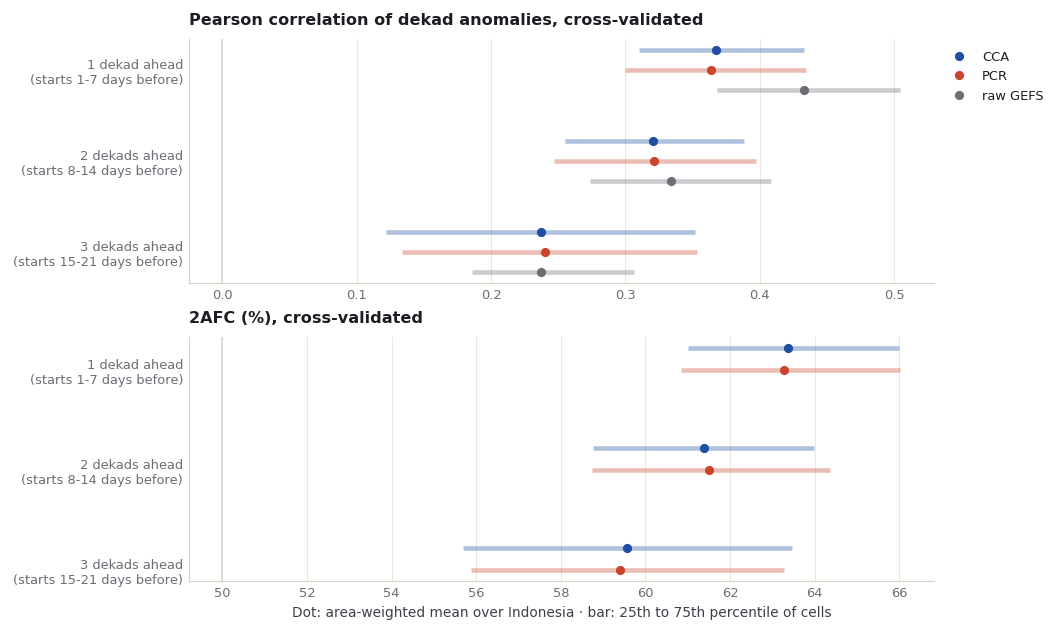

In [10]:
def quartiles(field):
    return np.nanpercentile(field.where(cells).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw GEFS": figures.MUTED}
panels = [("Pearson", "pearson", "Pearson correlation of dekad anomalies, cross-validated", 0),
          ("2AFC (%)", "two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 5.6), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw GEFS" and metric != "pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw GEFS" else clean(results[lead, method]["skill"][metric])
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [f"{lead} dekad{'s' if lead > 1 else ''} ahead\n(starts {7 * (lead - 1) + 1}-{7 * lead} days before)" for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of cells")
assets = repo / "docs/assets/dekad-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

Where the skill sits: CCA's cross-validated correlation at each lead, in one column.

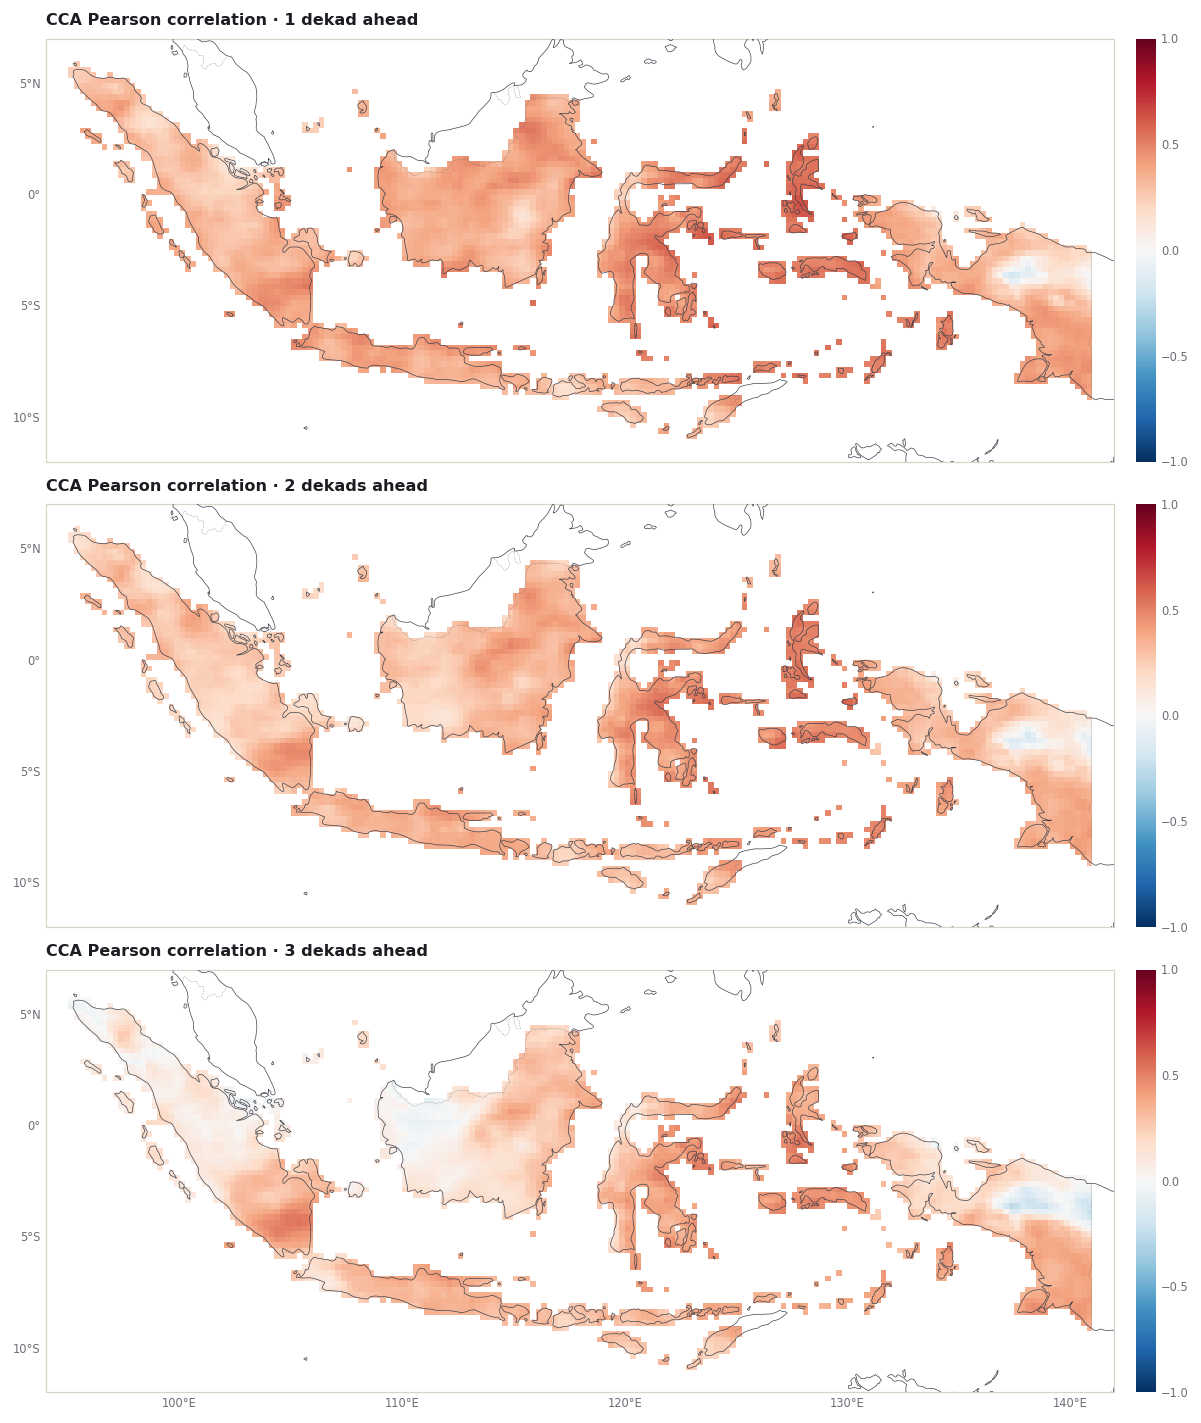

In [11]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, clean(results[lead, "CCA"]["skill"].pearson).where(cells), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · {lead} dekad{'s' if lead > 1 else ''} ahead")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 7. The nine dekads of October-December 2023

Observed and forecast anomalies, averaged over Indonesia's cells, for each dekad of
2023: the observations, then the CCA forecasts made one, two and three dekads
ahead (each from a different start).

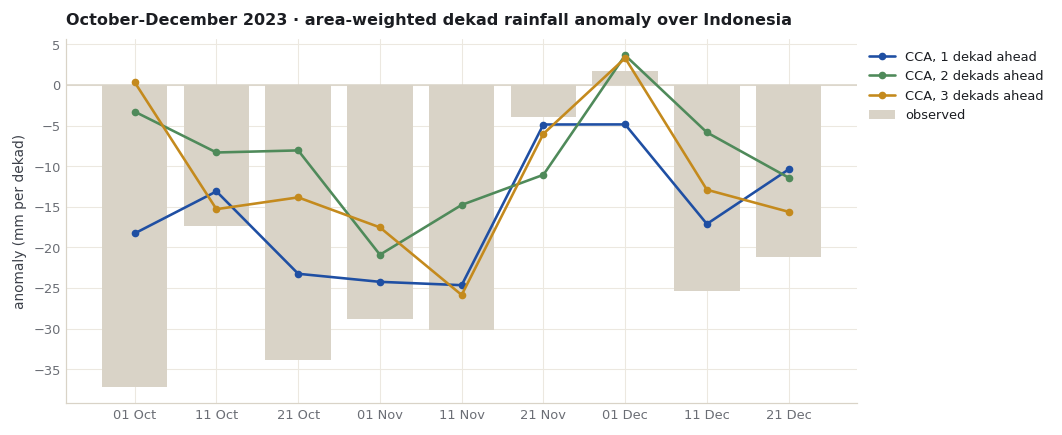

Observed area-mean anomalies (mm): {'01 Oct': np.float64(-37.2), '11 Oct': np.float64(-17.4), '21 Oct': np.float64(-33.8), '01 Nov': np.float64(-28.8), '11 Nov': np.float64(-30.1), '21 Nov': np.float64(-3.9), '01 Dec': np.float64(1.7), '11 Dec': np.float64(-25.3), '21 Dec': np.float64(-21.2)}


In [12]:
obs_2023 = y_anom.sel(T=test_T).where(obs.sel(T=test_T).notnull())
observed_series = obs_2023.weighted(weights).mean(("Y", "X"))
forecast_series = {}
for lead in leads:
    det = clean(results[lead, "CCA"]["forecast"].deterministic)
    det = det.drop_vars([c for c in det.coords if c not in ("T", "Y", "X")]).assign_coords(T=test_T)
    forecast_series[lead] = det.where(cells).weighted(weights).mean(("Y", "X"))

labels = [f"{pd.Timestamp(t):%d %b}" for t in test_T]
fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 3.8), layout="constrained")
ax.axhline(0, color=figures.LINE, linewidth=1)
ax.bar(np.arange(9), observed_series, color=figures.LINE, label="observed")
for lead, colour in zip(leads, [figures.ACCENT, figures.GREEN, figures.GOLD]):
    ax.plot(np.arange(9), forecast_series[lead], "o-", color=colour, markersize=4, label=f"CCA, {lead} dekad{'s' if lead > 1 else ''} ahead")
ax.set_xticks(np.arange(9), labels)
ax.set_ylabel("anomaly (mm per dekad)")
ax.set_title("October-December 2023 · area-weighted dekad rainfall anomaly over Indonesia")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "ond-2023-series.png")
plt.show()
print("Observed area-mean anomalies (mm):", dict(zip(labels, np.round(observed_series.values, 1))))

Each forecast also gives tercile probabilities. CPT defines its categories from the
training samples it was given, all 171 dekads together, so the observed category
uses the same definition: at each cell, below the 33rd or above the 67th percentile
of the 171 training anomalies (NumPy's `hazen` rule, as in
[chapter 5](../learn/05-probabilistic-forecasts.ipynb)). Scores over the nine 2023
dekads and all cells, area-weighted:

- **Hit rate**: share where the most likely category was the one observed. The
  reference is the share of the most frequent observed category (forecasting it
  everywhere every time would score that).
- **RPSS 2023**: ranked probability skill score against climatological odds
  (33/34/33%); above 0 is closer to what happened. Nine dekads of one season, not
  a skill estimate.

In [13]:
lower, upper = np.quantile(Y.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(lower, coords={"Y": Y["Y"], "X": Y["X"]}, dims=("Y", "X"))
upper = lower.copy(data=upper)
observed_category = xr.where(obs_2023 < lower, 0, xr.where(obs_2023 > upper, 2, 1)).where(obs_2023.notnull())
w3 = (weights * obs_2023.notnull()).astype(float)
shares = {name: float(w3.where(observed_category == k, 0).sum() / w3.sum() * 100)
          for k, name in enumerate(["below normal", "near normal", "above normal"])}
print("Observed categories, share of area x dekads (%):", {k: round(v, 1) for k, v in shares.items()})


def rps(probability, category):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(category <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


rows = []
for (lead, method), r in results.items():
    p = clean(r["forecast"].probabilistic)
    p = p.drop_vars([c for c in p.coords if c not in ("T", "C", "Y", "X")]).assign_coords(T=test_T)
    most_likely = p.fillna(-1).argmax("C").where(p.notnull().all("C") & observed_category.notnull())
    w = w3.where(most_likely.notnull(), 0)
    climatology = xr.DataArray([33.0, 34.0, 33.0], dims="C", coords={"C": p["C"]}).broadcast_like(p)
    det = clean(r["forecast"].deterministic)
    det = det.drop_vars([c for c in det.coords if c not in ("T", "Y", "X")]).assign_coords(T=test_T)
    rows.append({"lead": lead, "method": method,
                 "hit rate (%)": float(w.where(most_likely == observed_category, 0).sum() / w.sum() * 100),
                 "RPSS 2023": float(1 - rps(p, observed_category).weighted(w).mean() / rps(climatology, observed_category).weighted(w).mean()),
                 "RMSE 2023 (mm)": float(np.sqrt(((det - obs_2023) ** 2).weighted(w).mean())),
                 **{f"forecast {name} (%)": float(w.where(most_likely == k, 0).sum() / w.sum() * 100)
                    for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
print(f"Reference: the most frequent observed category covers {max(shares.values()):.1f}%")
forecast_2023.round(2)

Observed categories, share of area x dekads (%): {'below normal': 54.5, 'near normal': 31.1, 'above normal': 14.4}


Reference: the most frequent observed category covers 54.5%


hit rate (%)  RPSS 2023  RMSE 2023 (mm)  forecast below (%)  \
lead method                                                                
1    CCA            56.63       0.22           35.15               77.19   
     PCR            56.66       0.21           35.47               76.73   
2    CCA            48.86       0.10           39.08               60.86   
     PCR            47.38       0.10           39.33               61.16   
3    CCA            48.95       0.12           38.44               67.03   
     PCR            48.60       0.12           38.52               65.87   

             forecast near (%)  forecast above (%)  
lead method                                         
1    CCA                 12.01               10.81  
     PCR                 11.99               11.28  
2    CCA                 18.43               20.72  
     PCR                 17.93               20.91  
3    CCA                 11.20               21.77  
     PCR                 10.81               23.31

## 8. Save the results

The story page quotes these tables and shows these figures.

In [14]:
data_dir = repo / "docs/data/dekad-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-dekad-forecasts.csv")
pd.DataFrame({"dekad": labels, "observed": observed_series.values,
              **{f"cca_lead{lead}": forecast_series[lead].values for lead in leads}}).round(3).to_csv(
    data_dir / "ond-2023-area-anomalies.csv", index=False)
design.to_csv(data_dir / "lead-design.csv", index=False)
summary = {"target": "October-December 2023 dekads", "model": "GEFSv12 (IRI SubX GEFSv12_CPC)",
           "training_years": [training_years[0], training_years[-1]], "training_dekads": int(train.sum()),
           "cells": int(cells.sum()), "leads": leads, "lead_rule": "dekad starting 7(k-1)+1 to 7k days after a Wednesday start",
           "cross_validation_window": 17, "settings": {k: str(v) for k, v in cca_settings.items()},
           "observed_category_percent_2023": {k: round(v, 2) for k, v in shares.items()},
           "fit_seconds": {f"{lead}-{m}": round(r["seconds"], 1) for (lead, m), r in results.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset({f"{m.lower()}_pearson_lead{lead}": clean(r["skill"].pearson).where(cells).drop_vars(
    [c for c in r["skill"].pearson.coords if c not in ("Y", "X")], errors="ignore") for (lead, m), r in results.items()})
for lead in leads:
    maps[f"raw_pearson_lead{lead}"] = raw_pearson[lead]
save_netcdf(maps, data_dir / "dekad-leads-2023-maps.nc", overwrite=True,
            metadata={"note": "Cross-validated correlation of dekad rainfall anomalies, OND 2000-2018, GEFSv12 leads 1-3 dekads"})
for f in sorted(data_dir.iterdir()) + sorted(assets.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/dekad-leads-2023/dekad-leads-2023-maps.nc  (316 kB)
docs/data/dekad-leads-2023/lead-design.csv  (31 kB)
docs/data/dekad-leads-2023/ond-2023-area-anomalies.csv  (0 kB)
docs/data/dekad-leads-2023/ond-2023-dekad-forecasts.csv  (0 kB)
docs/data/dekad-leads-2023/skill-by-lead.csv  (0 kB)
docs/data/dekad-leads-2023/summary.json  (1 kB)
docs/assets/dekad-leads-2023/cca-pearson-by-lead.png  (595 kB)
docs/assets/dekad-leads-2023/ond-2023-series.png  (112 kB)
docs/assets/dekad-leads-2023/skill-by-lead.png  (105 kB)


## References {.unnumbered .reference-section}

1. IRI Data Library. *SubX EMC GEFSv12_CPC* (hindcast and forecast precipitation). <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.SubX/.EMC/.GEFSv12_CPC/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
2. Guan, H., Zhu, Y., Sinsky, E., et al. (2022). GEFSv12 reforecast dataset for supporting subseasonal and hydrometeorological applications. *Monthly Weather Review*, 150(3), 647-665. <https://doi.org/10.1175/MWR-D-21-0245.1>
3. BMKG. *Peringatan Dini Curah Hujan Dasarian* (dekadal rainfall early warnings by regency and city; showed dasarian I November 2026 when checked on 10 November 2026). <https://www.bmkg.go.id/iklim/peringatan-dini-hujan-tinggi>
4. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
5. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
6. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
7. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
8. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
9. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
10. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
11. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
12. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
13. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>